# 02 — Baseline next-day PM2.5 forecast for Lahore

**Goal:** can simple machine-learning models predict *tomorrow's* daily mean PM2.5 at the US Consulate monitor better than naive baselines?

**Set-up (kept deliberately honest):**
- Target: next-day (t+1) daily mean PM2.5, US Consulate Lahore monitor.
- **Chronological split** — train on May 2019 – Dec 2022, test on Jan 2023 – Feb 2025. No shuffling, so the model never sees the future.
- Baselines: *persistence* (tomorrow = today) and *climatology* (tomorrow = average for that calendar month in the training years).
- Models: Ridge regression, Random Forest, XGBoost. All of them predict the day-to-day *change* in log PM2.5 (tomorrow vs today), which is then applied to today's value.
- Two feature sets:
  - **A. Observed only** — pollution and weather up to and including today.
  - **B. A + tomorrow's weather** — uses ERA5 *reanalysis* for day t+1 as a stand-in for a weather forecast. This is an upper bound: a real system would use forecast weather, which has errors.
- Metrics: MAE, RMSE, R², and skill vs persistence. Also a simple "Very Unhealthy day" (PM2.5 > 150.4 µg/m³) alert check.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

ROOT = os.path.abspath("..")
VIS = os.path.join(ROOT, "visualizations")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
SEED = 42
df = pd.read_csv(os.path.join(ROOT, "data/processed/lahore_daily_merged.csv"), parse_dates=["date"]).set_index("date").asfreq("D")

## 1. Build features

In [2]:
pm = df["pm25_consulate"]
wx = ["temp_mean_c", "temp_min_c", "temp_range_c", "rh_mean_pct", "wind_speed_mean_kmh", "precip_mm",
      "pressure_mean_hpa", "blh_mean_m", "blh_night_mean_m", "cloud_cover_mean_pct"]
X = pd.DataFrame(index=df.index)
X["pm_today"] = pm
X["pm_lag1"] = pm.shift(1)
X["pm_lag2"] = pm.shift(2)
X["pm_mean7"] = pm.rolling(7, min_periods=4).mean()
X["log_pm_today"] = np.log(pm)
doy = df.index.day_of_year
X["doy_sin"], X["doy_cos"] = np.sin(2*np.pi*doy/365.25), np.cos(2*np.pi*doy/365.25)
for c in wx:
    X[c] = df[c]
X["wind_u"] = -df.wind_speed_mean_kmh * np.sin(np.deg2rad(df.wind_dir_vector_deg))
X["wind_v"] = -df.wind_speed_mean_kmh * np.cos(np.deg2rad(df.wind_dir_vector_deg))
X["fires_today"] = df.fires_punjab_region_total
X["fires_mean3"] = df.fires_punjab_region_total.rolling(3, min_periods=1).mean()
feat_A = list(X.columns)
for c in wx:
    X[c + "_tomorrow"] = df[c].shift(-1)
X["d_temp_min_tomorrow"] = X["temp_min_c_tomorrow"] - X["temp_min_c"]
X["d_blh_night_tomorrow"] = X["blh_night_mean_m_tomorrow"] - X["blh_night_mean_m"]
feat_B = list(X.columns)
y = pm.shift(-1).rename("pm_tomorrow")

data = X.join(y).dropna(subset=["pm_today", "pm_tomorrow"])
train = data[data.index < "2023-01-01"]
test = data[data.index >= "2023-01-01"]
print(f"train: {len(train)} days ({train.index.min().date()} – {train.index.max().date()})")
print(f"test:  {len(test)} days ({test.index.min().date()} – {test.index.max().date()})")

train: 779 days (2019-05-23 – 2022-10-24)
test:  579 days (2023-01-04 – 2025-02-16)


## 2. Baselines and models

In [3]:
def metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred)}

preds = {}
preds["Persistence (tomorrow = today)"] = test.pm_today.values
clim = train.groupby(train.index.month).pm_tomorrow.mean()
preds["Monthly climatology"] = test.index.map(lambda d: clim[(d + pd.Timedelta(days=1)).month]).values

def ridge():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=1.0))
def rf():
    return make_pipeline(SimpleImputer(strategy="median"),
                         RandomForestRegressor(n_estimators=500, min_samples_leaf=3, random_state=SEED, n_jobs=-1))
def xgb():
    return XGBRegressor(n_estimators=600, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                        min_child_weight=3, random_state=SEED)

fitted = {}
for fs_name, feats in [("A", feat_A), ("B", feat_B)]:
    for name, make in [("Ridge", ridge), ("Random Forest", rf), ("XGBoost", xgb)]:
        m = make()
        # Predict the *change* in log PM2.5 from today to tomorrow, then add it back to today's value.
        # Tree models cannot extrapolate beyond the training range (the Nov 2024 episode was far worse
        # than anything in 2019-2022), so modelling the change is more robust than modelling the level.
        m.fit(train[feats], np.log(train.pm_tomorrow) - np.log(train.pm_today))
        p = test.pm_today.values * np.exp(m.predict(test[feats]))
        key = f"{name} [{fs_name}]"
        preds[key] = p; fitted[key] = (m, feats)

rows = []
pers_mae = mean_absolute_error(test.pm_tomorrow, preds["Persistence (tomorrow = today)"])
for k, p in preds.items():
    r = metrics(test.pm_tomorrow, p); r["Skill vs persistence (MAE)"] = 1 - r["MAE"] / pers_mae
    rows.append(pd.Series(r, name=k))
results = pd.DataFrame(rows).round(3)
results

,MAE,RMSE,R2,Skill vs persistence (MAE)
Persistence (tomorrow = today),35.206,55.369,0.756,0.000
Monthly climatology,48.297,73.309,0.572,-0.372
Ridge [A],33.023,53.490,0.772,0.062
Random Forest [A],31.802,51.567,0.788,0.097
XGBoost [A],34.861,55.637,0.754,0.010
Ridge [B],28.739,46.727,0.826,0.184
Random Forest [B],28.553,44.523,0.842,0.189
XGBoost [B],35.511,54.467,0.764,-0.009


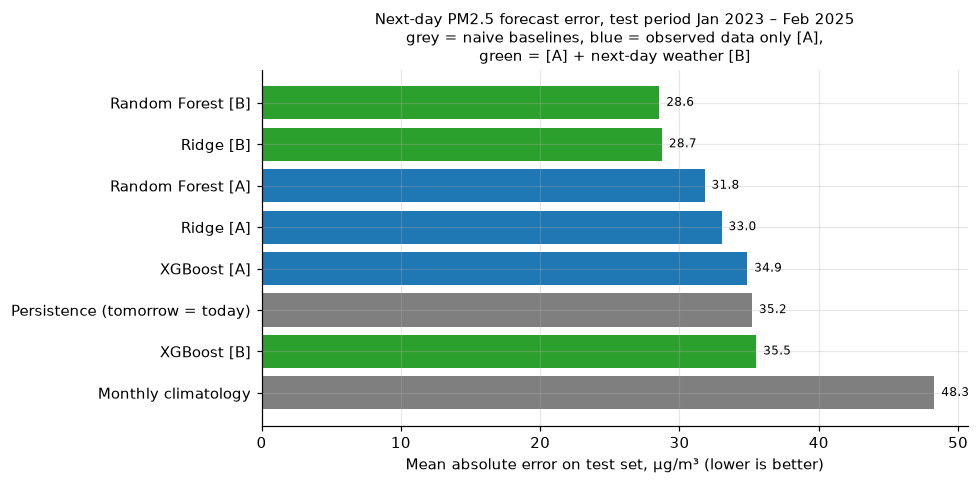

In [4]:
os.makedirs(os.path.join(ROOT, "models"), exist_ok=True)
results.to_csv(os.path.join(ROOT, "models", "baseline_results_test_2023_2025.csv"))

fig, ax = plt.subplots(figsize=(9, 4.5))
order = results.sort_values("MAE", ascending=False)
colors = ["tab:gray" if ("Persistence" in i or "climatology" in i) else ("tab:blue" if "[A]" in i else "tab:green") for i in order.index]
ax.barh(order.index, order.MAE, color=colors)
for i, v in enumerate(order.MAE):
    ax.text(v + 0.5, i, f"{v:.1f}", va="center", fontsize=8)
ax.set_xlabel("Mean absolute error on test set, µg/m³ (lower is better)")
ax.set_title("Next-day PM2.5 forecast error, test period Jan 2023 – Feb 2025\n"
             "grey = naive baselines, blue = observed data only [A],\ngreen = [A] + next-day weather [B]", fontsize=10)
fig.tight_layout(); fig.savefig(os.path.join(VIS, "fig09_forecast_model_comparison.png")); plt.show()

## 3. What does the forecast look like?

Best [A]: Random Forest [A] | Best [B]: Random Forest [B]


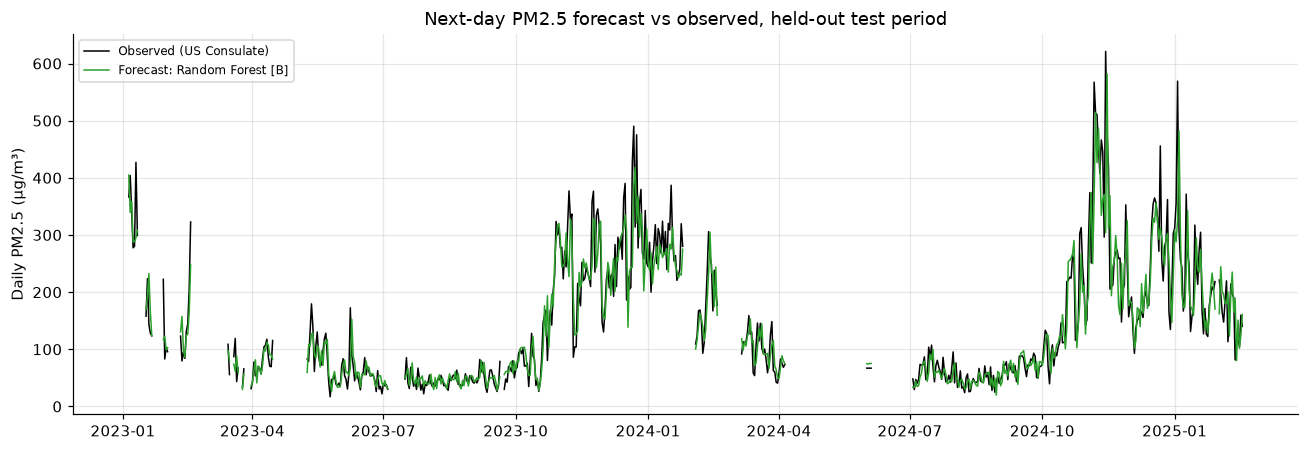

In [5]:
best_A = results.filter(like="[A]", axis=0).MAE.idxmin()
best_B = results.filter(like="[B]", axis=0).MAE.idxmin()
print("Best [A]:", best_A, "| Best [B]:", best_B)
plot = pd.DataFrame({"Observed": test.pm_tomorrow.values, best_B: preds[best_B], "Persistence": preds["Persistence (tomorrow = today)"]},
                    index=test.index + pd.Timedelta(days=1)).asfreq("D")
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(plot.index, plot.Observed, color="black", lw=1, label="Observed (US Consulate)")
ax.plot(plot.index, plot[best_B], color="tab:green", lw=1, label=f"Forecast: {best_B}")
ax.set_ylabel("Daily PM2.5 (µg/m³)")
ax.set_title("Next-day PM2.5 forecast vs observed, held-out test period")
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(VIS, "fig10_forecast_vs_observed.png")); plt.show()

## 4. Which inputs matter? (Random Forest impurity importance, feature set B)

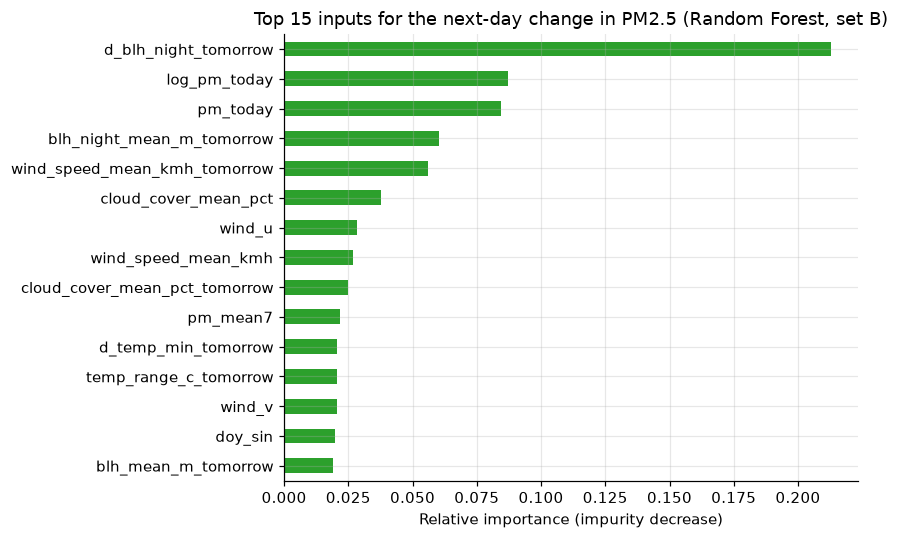

d_blh_night_tomorrow             0.213
log_pm_today                     0.087
pm_today                         0.084
blh_night_mean_m_tomorrow        0.060
wind_speed_mean_kmh_tomorrow     0.056
cloud_cover_mean_pct             0.038
wind_u                           0.028
wind_speed_mean_kmh              0.027
cloud_cover_mean_pct_tomorrow    0.025
pm_mean7                         0.022
d_temp_min_tomorrow              0.021
temp_range_c_tomorrow            0.021
wind_v                           0.021
doy_sin                          0.020
blh_mean_m_tomorrow              0.019
dtype: float64

In [6]:
m, feats = fitted["Random Forest [B]"]
imp = pd.Series(m[-1].feature_importances_, index=feats).sort_values(ascending=True).tail(15)
fig, ax = plt.subplots(figsize=(8, 5))
imp.plot.barh(ax=ax, color="tab:green")
ax.set_xlabel("Relative importance (impurity decrease)")
ax.set_title("Top 15 inputs for the next-day change in PM2.5 (Random Forest, set B)")
fig.tight_layout(); fig.savefig(os.path.join(VIS, "fig11_feature_importance.png")); plt.show()
imp.sort_values(ascending=False).round(3)

## 5. Early-warning view: can it flag "Very Unhealthy" days (PM2.5 > 150.4)?

In [7]:
thr = 150.4
obs = test.pm_tomorrow.values > thr
rows = []
for k in ["Persistence (tomorrow = today)", best_A, best_B]:
    pr = preds[k] > thr
    tp, fp, fn = (pr & obs).sum(), (pr & ~obs).sum(), (~pr & obs).sum()
    rows.append(pd.Series({"hit rate (recall)": tp/(tp+fn), "false alarm ratio": fp/max(tp+fp, 1),
                           "missed bad days": fn, "false alarms": fp, "bad days in test": obs.sum()}, name=k))
pd.DataFrame(rows).round(3)

,hit rate (recall),false alarm ratio,missed bad days,false alarms,bad days in test
Persistence (tomorrow = today),0.889,0.107,24.0,23.0,216.0
Random Forest [A],0.931,0.082,15.0,18.0,216.0
Random Forest [B],0.931,0.107,15.0,24.0,216.0


## 6. Honest interpretation
- Daily PM2.5 in Lahore is very **persistent**, so "tomorrow = today" is already a strong baseline. Any model has to beat that to be useful.
- Using only past observations (set A), the ML models give a modest improvement over persistence.
- XGBoost, with lightly chosen hyper-parameters and only ~780 training days, did **not** beat persistence. I have not tuned it yet; with this little data it probably over-fits. That is a week-2 task, not a conclusion that XGBoost is worse.
- Adding next-day weather (set B) helps more: changes in boundary-layer height, temperature and wind *between today and tomorrow* are what move PM2.5 up or down. This supports the idea that a useful early-warning system needs a **weather forecast as input**.
- Caveat: set B uses reanalysis weather for tomorrow (what actually happened), not a real forecast — real-world skill will be lower. Testing with archived weather *forecasts* is a next step.
- The test set is ~2 years from a single monitor; results should be treated as preliminary.

**Next steps (week 2):** walk-forward cross-validation, real weather-forecast inputs (e.g. Open-Meteo historical forecast API), calibrated CAMS / low-cost sensor data to extend the record past Feb 2025, and 2–3 day lead times.